# Exercise 2 – CNN Baseline and MLP Comparison

Train the three-layer CNN baseline on CIFAR-10 using the same split and training settings as Exercise 1. Use validation loss to save a best-validation checkpoint; use the official test set only after training to report the final and early-stopped models.

## 1. CNNs for image classification

Convolutions learn local patterns with shared weights, so a feature detector can recognize an edge or texture at different image positions. Pooling reduces spatial size and provides some tolerance to small shifts. Stacked layers can combine edges into textures and object parts. An MLP instead flattens the image and uses dense weights, which do not directly preserve local neighborhoods.

## 2. Shared setup and reproducibility

This notebook uses the same seed-42 split, normalization, batch size, epoch count, optimizer, and learning rate as Exercises 1 and 4. CIFAR-10 is downloaded only if its local folder is missing.

In [1]:
import json
import sys
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
DATA_DIR = PROJECT_ROOT / "data"
CIFAR_DIR = DATA_DIR / "cifar-10-batches-py"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_2"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DOWNLOAD_DATA = not CIFAR_DIR.exists()
print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: CUDA is unavailable; this training will run on CPU.")


Python: D:\AI ML\AI-ML-assessment-cifar10-project\.venv\Scripts\python.exe
PyTorch: 2.14.1+cu126
CUDA available: True
Project: D:\AI ML\AI-ML-assessment-cifar10-project
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 3. Preprocessing, split, and loaders

The exact same seeded permutation is used in Exercises 1 and 4. The official test partition is not loaded here. A dedicated generator fixes the shuffled training order.

In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
download = not (DATA_DIR / "cifar-10-batches-py").exists()
DOWNLOAD_DATA = download
train_val_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=download, transform=transform
)
assert len(train_val_dataset) == 50_000
split_indices = torch.randperm(
    50_000, generator=torch.Generator().manual_seed(42)
).tolist()
train_dataset = Subset(train_val_dataset, split_indices[:45_000])
val_dataset = Subset(train_val_dataset, split_indices[45_000:])
loader_args = {"batch_size": BATCH_SIZE, "num_workers": 0, "pin_memory": DEVICE.type == "cuda"}
train_loader = DataLoader(
    train_dataset, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_args,
)
train_eval_loader = DataLoader(train_dataset, shuffle=False, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)
CLASS_NAMES = train_val_dataset.classes
print(f"Training: {len(train_dataset):,}; validation: {len(val_dataset):,}")


Training: 45,000; validation: 5,000


## 4. Three-layer CNN baseline

Two 3×3 convolutions use 32 and 64 filters. ReLU and 2×2 max pooling follow each convolution. A 32×32 image becomes an 8×8 feature map, so the final Linear layer maps 4,096 features to ten classes. The model has exactly three trainable layers and 60,362 parameters.


In [3]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        return self.fc(self.flatten(x))

model = CIFAR10CNN().to(DEVICE)
trainable_layers = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
assert len(trainable_layers) == 3
TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert TRAINABLE_PARAMETERS == 60_362
print(model)
print("Trainable layers:", len(trainable_layers))
print("Trainable parameters:", f"{TRAINABLE_PARAMETERS:,}")


CIFAR10CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable layers: 3
Trainable parameters: 60,362


## 5. Training, validation, and best-validation-loss checkpoint

The epoch loop is shared with the width baseline in Exercise 4. Training and validation loss and accuracy are recorded every epoch. The best checkpoint is selected by validation loss only; the test set is not involved.

In [4]:
criterion = nn.CrossEntropyLoss()

def epoch_metrics(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            try:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                if training:
                    optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                loss = criterion(logits, labels)
                if training:
                    loss.backward()
                    optimizer.step()
                n = labels.size(0)
                sample_count += n
                loss_sum += loss.item() * n
                correct += (logits.argmax(1) == labels).sum().item()
            except torch.cuda.OutOfMemoryError as exc:
                if training:
                    optimizer.zero_grad(set_to_none=True)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                raise RuntimeError(
                    "CUDA out of memory. Run stopped without retry. Reduce BATCH_SIZE, recreate the model and optimizer, then restart."
                ) from exc
    return loss_sum / sample_count, correct / sample_count

def evaluate(model, loader, collect_predictions=False):
    model.eval()
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            n = labels.size(0)
            sample_count += n
            loss_sum += loss.item() * n
            predictions = logits.argmax(1)
            correct += (predictions == labels).sum().item()
            if collect_predictions:
                y_true.extend(labels.cpu().tolist())
                y_pred.extend(predictions.cpu().tolist())
    metrics = (loss_sum / sample_count, correct / sample_count)
    return (*metrics, y_true, y_pred) if collect_predictions else metrics

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {key: [] for key in ("train_loss", "train_accuracy", "val_loss", "val_accuracy")}
best_val_loss = float("inf")
best_val_loss_epoch = None
BEST_CHECKPOINT = ARTIFACT_DIR / "cnn_baseline_best_val_loss.pth"
training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = epoch_metrics(model, train_loader, optimizer)
    val_loss, val_accuracy = epoch_metrics(model, val_loader)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_loss_epoch = epoch
        torch.save(model.state_dict(), BEST_CHECKPOINT)
    print(
        f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, train accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, val accuracy {val_accuracy:.4f} | best val loss {best_val_loss:.4f} (epoch {best_val_loss_epoch})"
    )
training_seconds = time.perf_counter() - training_start
print(f"Training time: {training_seconds:.1f} seconds")


Epoch 1/20 | train loss 1.3196, train accuracy 0.5347 | val loss 1.0738, val accuracy 0.6226 | best val loss 1.0738 (epoch 1)


Epoch 2/20 | train loss 0.9764, train accuracy 0.6604 | val loss 0.9738, val accuracy 0.6640 | best val loss 0.9738 (epoch 2)


Epoch 3/20 | train loss 0.8476, train accuracy 0.7063 | val loss 0.8985, val accuracy 0.6908 | best val loss 0.8985 (epoch 3)


Epoch 4/20 | train loss 0.7583, train accuracy 0.7392 | val loss 0.8850, val accuracy 0.6964 | best val loss 0.8850 (epoch 4)


Epoch 5/20 | train loss 0.6918, train accuracy 0.7626 | val loss 0.8843, val accuracy 0.7056 | best val loss 0.8843 (epoch 5)


Epoch 6/20 | train loss 0.6389, train accuracy 0.7816 | val loss 0.8441, val accuracy 0.7144 | best val loss 0.8441 (epoch 6)


... (10 outputs left out)

Epoch 17/20 | train loss 0.3058, train accuracy 0.8920 | val loss 1.2306, val accuracy 0.6834 | best val loss 0.8440 (epoch 7)


Epoch 18/20 | train loss 0.2853, train accuracy 0.8981 | val loss 1.2782, val accuracy 0.6868 | best val loss 0.8440 (epoch 7)


Epoch 19/20 | train loss 0.2710, train accuracy 0.9025 | val loss 1.2746, val accuracy 0.6884 | best val loss 0.8440 (epoch 7)


Epoch 20/20 | train loss 0.2592, train accuracy 0.9088 | val loss 1.3634, val accuracy 0.6786 | best val loss 0.8440 (epoch 7)
Training time: 258.4 seconds


## 6. Learning curves and final evaluation-mode metrics

Plot the training history, then evaluate the final-epoch model on the complete training and validation subsets in evaluation mode. These clean metrics are distinct from the online training metrics recorded each epoch.

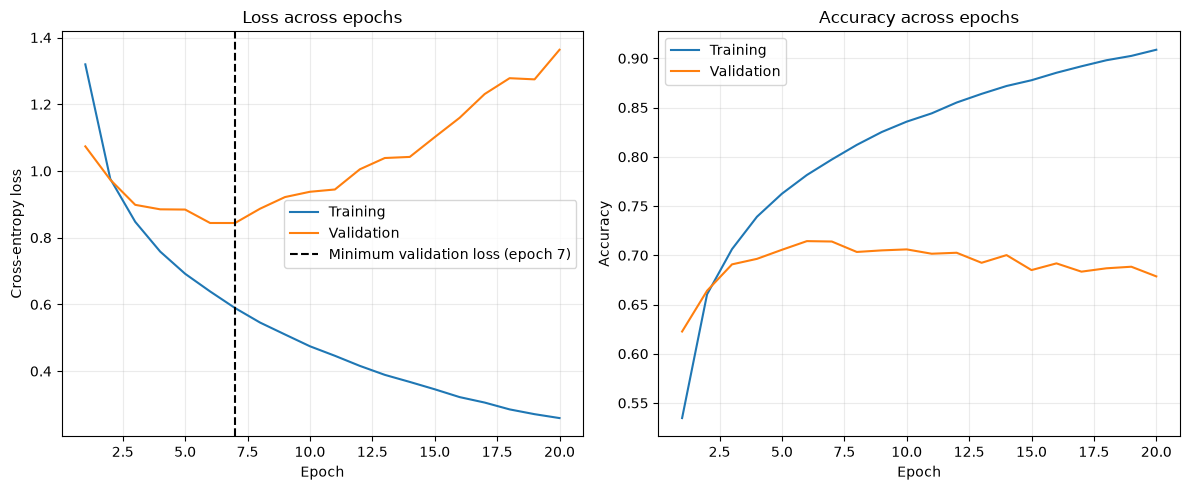

Final-epoch eval-mode train: loss=0.2271, accuracy=0.9209
Final-epoch validation: loss=1.3634, accuracy=0.6786


In [5]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(epochs, history["train_loss"], label="Training")
axes[0].plot(epochs, history["val_loss"], label="Validation")
min_val_loss_epoch = int(np.argmin(history["val_loss"]) + 1)
axes[0].axvline(min_val_loss_epoch, color="black", linestyle="--",
                label=f"Minimum validation loss (epoch {min_val_loss_epoch})")
axes[0].set(title="Loss across epochs", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].plot(epochs, history["train_accuracy"], label="Training")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy across epochs", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.25)
fig.tight_layout(); fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=160); plt.show()
final_train_loss, final_train_accuracy = evaluate(model, train_eval_loader)
final_val_loss, final_val_accuracy = evaluate(model, val_loader)
print("Final-epoch eval-mode train:", f"loss={final_train_loss:.4f}, accuracy={final_train_accuracy:.4f}")
print("Final-epoch validation:", f"loss={final_val_loss:.4f}, accuracy={final_val_accuracy:.4f}")


### Learned filters and feature maps

The following figures use final-epoch convolution weights and two validation images. They are descriptive visualisations, not a semantic interpretation of individual filters.

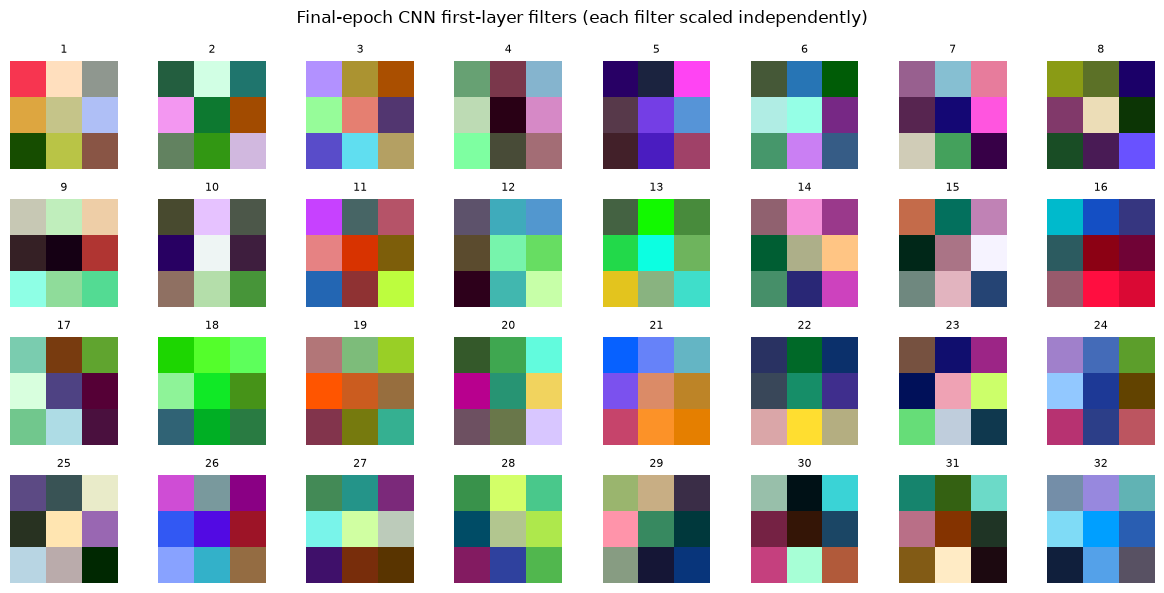

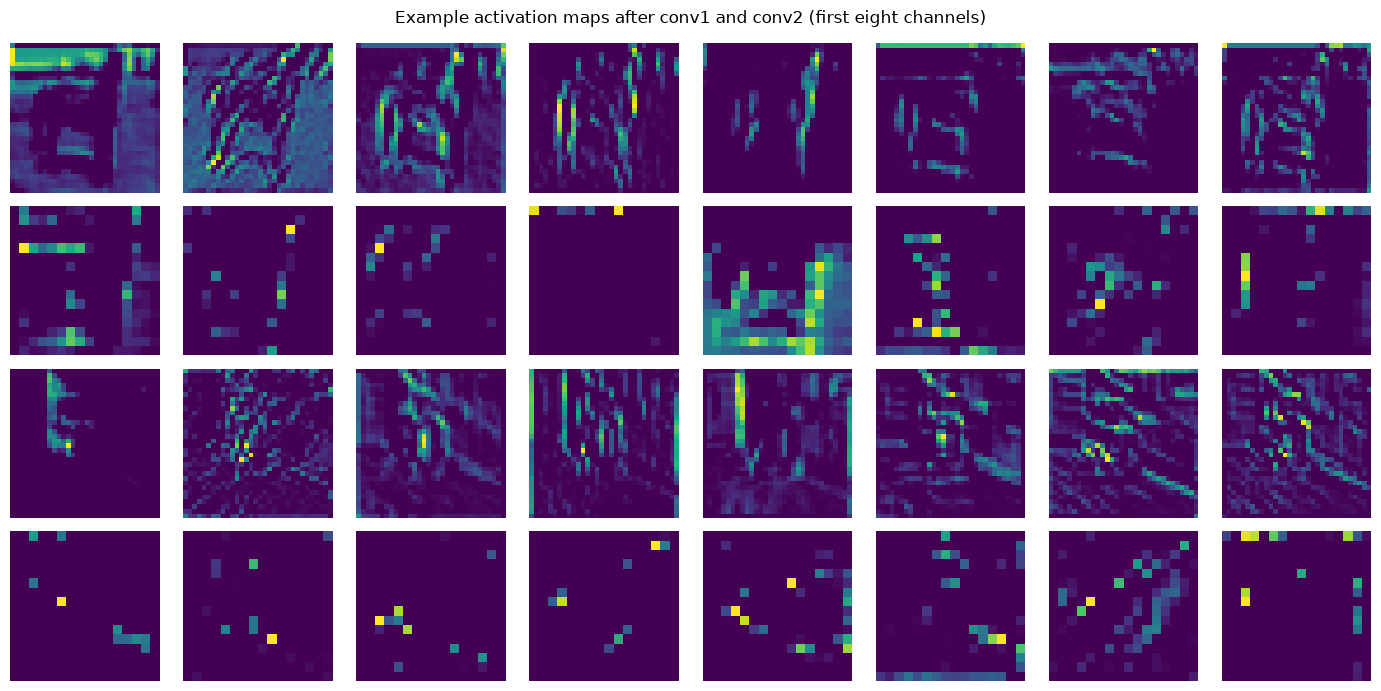

The filter figure shows all 32 first-layer filters, each scaled for display. The feature-map figure shows the first 8 channels from conv1 and conv2 for two validation images (horse and truck). Their displayed activations span 0.000 to 4.633 after conv1 and 0.000 to 4.307 after conv2. The patterns vary by channel and location; these images alone do not establish that a particular filter detects a specific semantic feature.

426

In [6]:
conv1_weights = model.conv1.weight.detach().cpu()
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for filter_index, ax in enumerate(axes.flat):
    weight = conv1_weights[filter_index].permute(1, 2, 0).numpy()
    low, high = weight.min(), weight.max()
    display_filter = (weight - low) / (high - low) if high > low else np.zeros_like(weight)
    ax.imshow(display_filter)
    ax.set_title(str(filter_index + 1), fontsize=8)
    ax.axis("off")
fig.suptitle("Final-epoch CNN first-layer filters (each filter scaled independently)")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "cnn_conv1_filters.png", dpi=160)
plt.show()
plt.close(fig)

validation_examples = [val_dataset[i] for i in (0, 1)]
example_images = torch.stack([image for image, _ in validation_examples]).to(DEVICE)
example_labels = [CLASS_NAMES[label] for _, label in validation_examples]
model.eval()
with torch.no_grad():
    conv1_maps = model.relu1(model.conv1(example_images))
    conv2_maps = model.relu2(model.conv2(model.pool1(conv1_maps)))
shown_channels = 8
fig, axes = plt.subplots(4, shown_channels, figsize=(14, 7))
for image_index in range(2):
    for channel in range(shown_channels):
        for layer_index, maps in enumerate((conv1_maps, conv2_maps)):
            row = image_index * 2 + layer_index
            feature_map = maps[image_index, channel].detach().cpu().numpy()
            axes[row, channel].imshow(feature_map, cmap="viridis")
            axes[row, channel].axis("off")
            if channel == 0:
                layer_name = "conv1" if layer_index == 0 else "conv2"
                axes[row, channel].set_ylabel(
                    f"Validation {image_index + 1} ({example_labels[image_index]})\n{layer_name}",
                    fontsize=8,
                )
fig.suptitle("Example activation maps after conv1 and conv2 (first eight channels)")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "cnn_validation_feature_maps.png", dpi=160)
plt.show()
plt.close(fig)

conv1_range = (float(conv1_maps.min().item()), float(conv1_maps.max().item()))
conv2_range = (float(conv2_maps.min().item()), float(conv2_maps.max().item()))
feature_description = (
    f"The filter figure shows all {conv1_weights.shape[0]} first-layer filters, each scaled for display. "
    f"The feature-map figure shows the first {shown_channels} channels from conv1 and conv2 for two "
    f"validation images ({example_labels[0]} and {example_labels[1]}). Their displayed activations span "
    f"{conv1_range[0]:.3f} to {conv1_range[1]:.3f} after conv1 and {conv2_range[0]:.3f} to "
    f"{conv2_range[1]:.3f} after conv2. The patterns vary by channel and location; these images alone "
    "do not establish that a particular filter detects a specific semantic feature."
)
display(Markdown(feature_description))
(ARTIFACT_DIR / "feature_visualisation.md").write_text(feature_description + "\n", encoding="utf-8")


## 7. Final and early-stopped baseline evaluation

Only after training is complete, load the official test set. Evaluate the final-epoch model and the checkpoint selected by lowest validation loss. Test results are reported, not used to select either model.

Final-epoch official test loss: 1.3832
Final-epoch official test accuracy: 0.6850 (68.50%)


Early-stopped checkpoint: epoch 7, selected by validation loss
Early-stopped official test loss: 0.8596
Early-stopped official test accuracy: 0.7143 (71.43%)
              precision    recall  f1-score   support

    airplane       0.68      0.75      0.71      1000
  automobile       0.83      0.76      0.80      1000
        bird       0.53      0.61      0.57      1000
         cat       0.56      0.43      0.48      1000
        deer       0.56      0.76      0.65      1000
         dog       0.66      0.56      0.61      1000
        frog       0.77      0.74      0.75      1000
       horse       0.75      0.71      0.73      1000
        ship       0.80      0.78      0.79      1000
       truck       0.76      0.75      0.76      1000

    accuracy                           0.69     10000
   macro avg       0.69      0.68      0.68     10000
weighted avg       0.69      0.69      0.68     10000



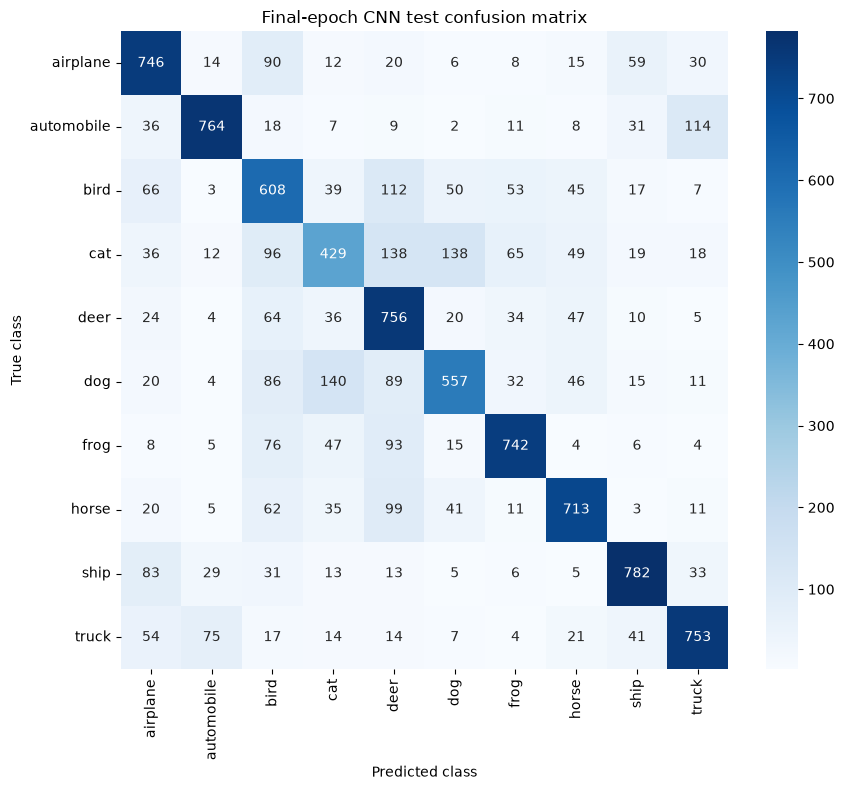

In [7]:
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=DOWNLOAD_DATA, transform=transform
)
assert len(test_dataset) == 10_000
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)
final_test_loss, final_test_accuracy, y_true, y_pred = evaluate(model, test_loader, collect_predictions=True)
print(f"Final-epoch official test loss: {final_test_loss:.4f}")
print(f"Final-epoch official test accuracy: {final_test_accuracy:.4f} ({100 * final_test_accuracy:.2f}%)")

best_model = CIFAR10CNN().to(DEVICE)
best_model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=DEVICE, weights_only=True))
best_train_loss, best_train_accuracy = evaluate(best_model, train_eval_loader)
best_val_loss_eval, best_val_accuracy = evaluate(best_model, val_loader)
best_test_loss, best_test_accuracy = evaluate(best_model, test_loader)
print(f"Early-stopped checkpoint: epoch {best_val_loss_epoch}, selected by validation loss")
print(f"Early-stopped official test loss: {best_test_loss:.4f}")
print(f"Early-stopped official test accuracy: {best_test_accuracy:.4f} ({100 * best_test_accuracy:.2f}%)")
report_text = classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
print(report_text)
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel="Predicted class", ylabel="True class", title="Final-epoch CNN test confusion matrix")
fig.tight_layout(); fig.savefig(ARTIFACT_DIR / "test_confusion_matrix.png", dpi=160); plt.show()


## 8. Save checkpoints and measured results

The primary baseline is the final-epoch model. The second checkpoint is selected using validation loss only and is labeled the early-stopped baseline.

In [8]:
FINAL_CHECKPOINT = ARTIFACT_DIR / "cnn_baseline_final_epoch.pth"
torch.save(model.cpu().state_dict(), FINAL_CHECKPOINT)
torch.save(model.state_dict(), ARTIFACT_DIR / "cnn_baseline.pth")
model.to(DEVICE)
final_metrics = {
    "train": {"loss": final_train_loss, "accuracy": final_train_accuracy},
    "validation": {"loss": final_val_loss, "accuracy": final_val_accuracy},
    "test": {"loss": final_test_loss, "accuracy": final_test_accuracy},
}
best_metrics = {
    "epoch": best_val_loss_epoch,
    "selection_metric": "validation_loss",
    "best_validation_loss": best_val_loss,
    "train": {"loss": best_train_loss, "accuracy": best_train_accuracy},
    "validation": {"loss": best_val_loss_eval, "accuracy": best_val_accuracy},
    "test": {"loss": best_test_loss, "accuracy": best_test_accuracy},
}
results = {
    "seed": SEED, "split_seed": 42, "device": str(DEVICE),
    "trainable_layers": len(trainable_layers), "trainable_parameters": TRAINABLE_PARAMETERS,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
    "split_sizes": {"train": len(train_dataset), "validation": len(val_dataset), "official_test": len(test_dataset)},
    "training_seconds": training_seconds, "history": history,
    "final_epoch": {"checkpoint": str(FINAL_CHECKPOINT.relative_to(PROJECT_ROOT)), "metrics": final_metrics},
    "best_validation_loss": {"checkpoint": str(BEST_CHECKPOINT.relative_to(PROJECT_ROOT)), **best_metrics},
    "classification_report": report,
}
results_path = ARTIFACT_DIR / "results.json"
if results_path.exists():
    previous_results = json.loads(results_path.read_text(encoding="utf-8"))
    expected = {
        ("train", "accuracy"): 0.9209,
        ("validation", "accuracy"): 0.6786,
        ("test", "accuracy"): 0.6850,
    }
    for (split, metric), reference in expected.items():
        actual = final_metrics[split][metric]
        if abs(actual - reference) > 0.0001:
            raise RuntimeError(
                f"Exercise 2 reference mismatch for {split} {metric}: {actual:.8f} vs {reference:.8f}; stop and review."
            )
    results = previous_results
else:
    with results_path.open("w", encoding="utf-8") as f:
        json.dump(results, f, indent=2)
with (ARTIFACT_DIR / "classification_report.json").open("w", encoding="utf-8") as f: json.dump(report, f, indent=2)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(ARTIFACT_DIR / "test_confusion_matrix.csv", index_label="true_label")
print("Saved final and best-validation checkpoints and measured results to:", ARTIFACT_DIR)


Saved final and best-validation checkpoints and measured results to: D:\AI ML\AI-ML-assessment-cifar10-project\artifacts\exercise_2


## 9. MLP versus CNN comparison

Load the saved Exercise 1 measurements and compare both models using final evaluation-mode metrics. The figures use recorded histories and per-class test recall.

,model,checkpoint,selected_epoch,trainable_parameters,train_accuracy,train_loss,validation_accuracy,validation_loss,test_accuracy,test_loss,train_test_accuracy_gap_pp,selection_metric
0,MLP,Final epoch,20,1707274,0.842289,0.446415,0.5168,2.218918,0.5165,2.190231,32.578889,Final epoch
1,MLP,Best validation-loss checkpoint,5,1707274,0.612467,1.096525,0.5050,1.422094,0.5090,1.429543,10.346667,Validation loss
2,CNN,Final epoch,20,60362,0.920889,0.227102,0.6786,1.363420,0.6850,1.383230,23.588889,Final epoch
3,CNN,Best validation-loss checkpoint,7,60362,0.838667,0.487005,0.7140,0.844022,0.7143,0.859613,12.436667,Validation loss


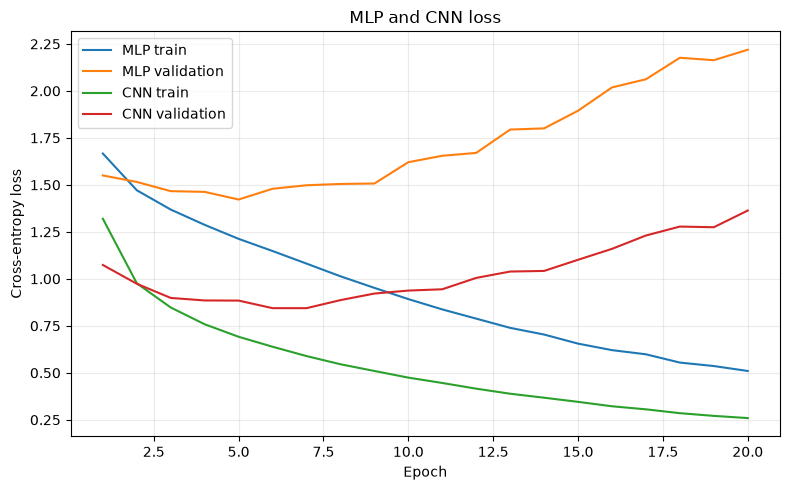

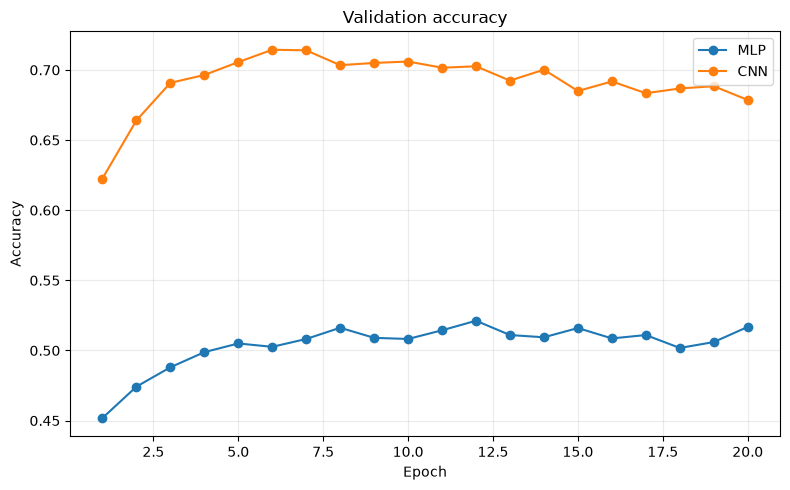

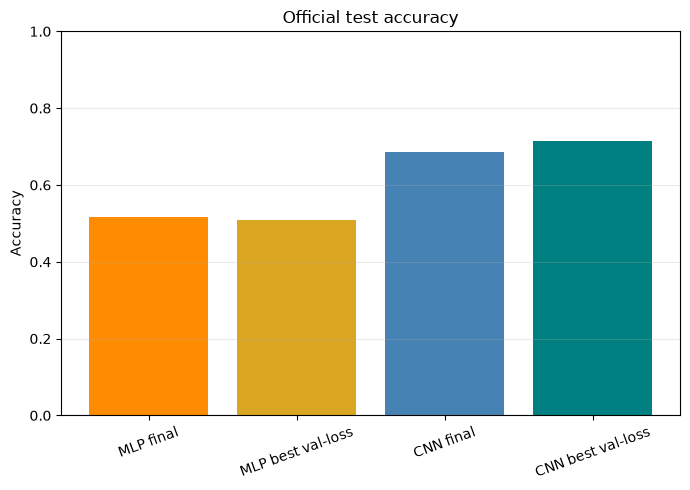

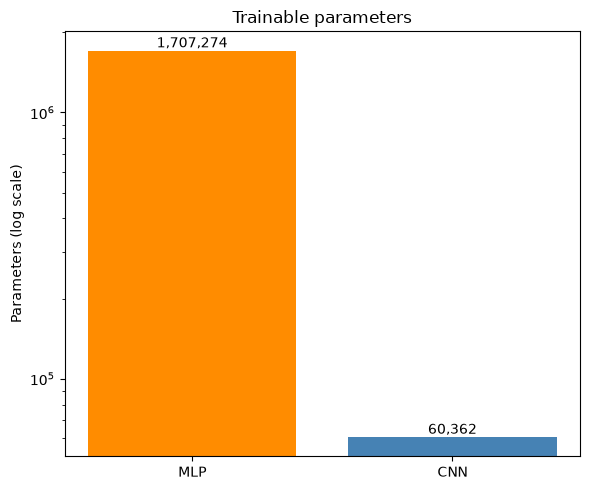

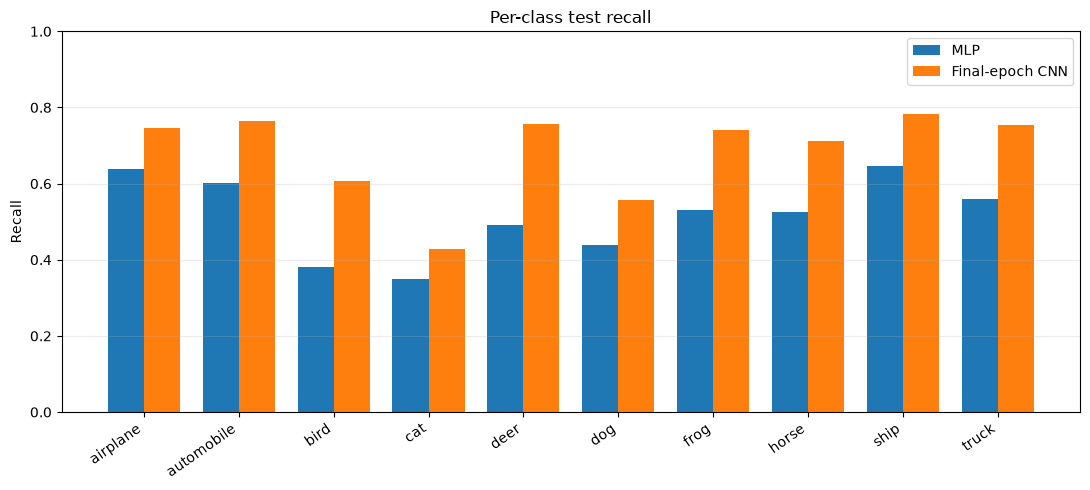

In [9]:
mlp_results_path = PROJECT_ROOT / "artifacts" / "exercise_1" / "results.json"
if not mlp_results_path.exists():
    raise FileNotFoundError("Run notebooks/Exercise_1_MLP.ipynb first; its results.json is required for Exercise 2.")
mlp_results = json.loads(mlp_results_path.read_text(encoding="utf-8"))
mlp_metrics = mlp_results["final_metrics"]
mlp_best_metrics = mlp_results["best_validation_loss"]
mlp_train_test_gap_pp = 100 * (mlp_metrics["train"]["accuracy"] - mlp_metrics["test"]["accuracy"])
mlp_best_train_test_gap_pp = 100 * (mlp_best_metrics["train"]["accuracy"] - mlp_best_metrics["test"]["accuracy"])
cnn_train_test_gap_pp = 100 * (final_train_accuracy - final_test_accuracy)
best_train_test_gap_pp = 100 * (best_train_accuracy - best_test_accuracy)
parameter_ratio = mlp_results["trainable_parameters"] / TRAINABLE_PARAMETERS
comparison = pd.DataFrame([
    {"model":"MLP", "checkpoint":"Final epoch", "selected_epoch":mlp_results["epochs"],
     "trainable_parameters":mlp_results["trainable_parameters"],
     "train_accuracy":mlp_metrics["train"]["accuracy"], "train_loss":mlp_metrics["train"]["loss"],
     "validation_accuracy":mlp_metrics["validation"]["accuracy"], "validation_loss":mlp_metrics["validation"]["loss"],
     "test_accuracy":mlp_metrics["test"]["accuracy"], "test_loss":mlp_metrics["test"]["loss"],
     "train_test_accuracy_gap_pp":mlp_train_test_gap_pp, "selection_metric":"Final epoch"},
    {"model":"MLP", "checkpoint":"Best validation-loss checkpoint", "selected_epoch":mlp_best_metrics["epoch"],
     "trainable_parameters":mlp_results["trainable_parameters"],
     "train_accuracy":mlp_best_metrics["train"]["accuracy"], "train_loss":mlp_best_metrics["train"]["loss"],
     "validation_accuracy":mlp_best_metrics["validation"]["accuracy"], "validation_loss":mlp_best_metrics["validation"]["loss"],
     "test_accuracy":mlp_best_metrics["test"]["accuracy"], "test_loss":mlp_best_metrics["test"]["loss"],
     "train_test_accuracy_gap_pp":mlp_best_train_test_gap_pp, "selection_metric":"Validation loss"},
    {"model":"CNN", "checkpoint":"Final epoch", "selected_epoch":EPOCHS,
     "trainable_parameters":TRAINABLE_PARAMETERS,
     "train_accuracy":final_train_accuracy, "train_loss":final_train_loss,
     "validation_accuracy":final_val_accuracy, "validation_loss":final_val_loss,
     "test_accuracy":final_test_accuracy, "test_loss":final_test_loss,
     "train_test_accuracy_gap_pp":cnn_train_test_gap_pp, "selection_metric":"Final epoch"},
    {"model":"CNN", "checkpoint":"Best validation-loss checkpoint", "selected_epoch":best_val_loss_epoch,
     "trainable_parameters":TRAINABLE_PARAMETERS,
     "train_accuracy":best_train_accuracy, "train_loss":best_train_loss,
     "validation_accuracy":best_val_accuracy, "validation_loss":best_val_loss_eval,
     "test_accuracy":best_test_accuracy, "test_loss":best_test_loss,
     "train_test_accuracy_gap_pp":best_train_test_gap_pp, "selection_metric":"Validation loss"},
])
display(comparison)
comparison.to_csv(ARTIFACT_DIR / "mlp_cnn_comparison.csv", index=False)
mlp_history = mlp_results["history"]

fig, ax = plt.subplots(figsize=(8,5))
for key,label in [("train_loss","MLP train"),("val_loss","MLP validation")]:
    ax.plot(range(1,len(mlp_history[key])+1),mlp_history[key],label=label)
for key,label in [("train_loss","CNN train"),("val_loss","CNN validation")]:
    ax.plot(range(1,len(history[key])+1),history[key],label=label)
ax.set(title="MLP and CNN loss",xlabel="Epoch",ylabel="Cross-entropy loss")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"mlp_cnn_loss_comparison.png",dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(8,5))
ax.plot(range(1,len(mlp_history["val_accuracy"])+1),mlp_history["val_accuracy"],marker="o",label="MLP")
ax.plot(range(1,len(history["val_accuracy"])+1),history["val_accuracy"],marker="o",label="CNN")
ax.set(title="Validation accuracy",xlabel="Epoch",ylabel="Accuracy")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"mlp_cnn_validation_accuracy.png",dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(7,5))
bar_labels=["MLP final","MLP best val-loss","CNN final","CNN best val-loss"]
bar_values=[mlp_metrics["test"]["accuracy"],mlp_best_metrics["test"]["accuracy"],final_test_accuracy,best_test_accuracy]
ax.bar(bar_labels,bar_values,color=["darkorange","goldenrod","steelblue","teal"])
ax.tick_params(axis="x", labelrotation=20)
ax.set(title="Official test accuracy",ylabel="Accuracy",ylim=(0,1)); ax.grid(axis="y",alpha=.25)
fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"mlp_cnn_test_accuracy.png",dpi=160); plt.show()

counts=[mlp_results["trainable_parameters"],TRAINABLE_PARAMETERS]
fig,ax=plt.subplots(figsize=(6,5)); ax.bar(["MLP","CNN"],counts,color=["darkorange","steelblue"])
ax.set_yscale("log"); ax.set(title="Trainable parameters",ylabel="Parameters (log scale)")
for i,value in enumerate(counts): ax.text(i,value,f"{value:,}",ha="center",va="bottom")
fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"mlp_cnn_parameters.png",dpi=160); plt.show()

mlp_recalls=[mlp_results["classification_report"][name]["recall"] for name in CLASS_NAMES]
cnn_recalls=[report[name]["recall"] for name in CLASS_NAMES]
x=np.arange(len(CLASS_NAMES)); width=.38
fig,ax=plt.subplots(figsize=(11,5))
ax.bar(x-width/2,mlp_recalls,width,label="MLP"); ax.bar(x+width/2,cnn_recalls,width,label="Final-epoch CNN")
ax.set_xticks(x,CLASS_NAMES,rotation=35,ha="right")
ax.set(title="Per-class test recall",ylabel="Recall",ylim=(0,1))
ax.legend(); ax.grid(axis="y",alpha=.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"mlp_cnn_class_recall.png",dpi=160); plt.show()

## 10. Discussion

The discussion is generated from the executed measurements. Test results are descriptive and were not used to select a checkpoint.


In [10]:
mlp_test_accuracy = mlp_metrics["test"]["accuracy"]
mlp_early_test_accuracy = mlp_best_metrics["test"]["accuracy"]
cnn_test_difference_pp = 100 * (final_test_accuracy - mlp_test_accuracy)
cnn_early_difference_pp = 100 * (best_test_accuracy - mlp_early_test_accuracy)
early_stop_gain_pp = 100 * (best_test_accuracy - final_test_accuracy)
cnn_val_loss_min_epoch = int(np.argmin(history["val_loss"]) + 1)
parameter_ratio = mlp_results["trainable_parameters"] / TRAINABLE_PARAMETERS
cnn_train_test_gap_pp = 100 * (final_train_accuracy - final_test_accuracy)
mlp_train_test_gap_pp = 100 * (mlp_metrics["train"]["accuracy"] - mlp_test_accuracy)
cnn_discussion = f"""### Measured comparison

The final-epoch CNN test accuracy was **{final_test_accuracy:.2%}**, compared with **{mlp_test_accuracy:.2%}** for the final-epoch MLP, a difference of **{cnn_test_difference_pp:+.2f} percentage points (pp)**. The MLP has {mlp_results['trainable_parameters']:,} parameters versus {TRAINABLE_PARAMETERS:,} for the CNN, or **{parameter_ratio:.2f} times** as many. The final-epoch CNN train-to-test accuracy gap was **{cnn_train_test_gap_pp:.2f} pp** (the MLP gap was {mlp_train_test_gap_pp:.2f} pp).

The MLP best-validation-loss checkpoint was selected at epoch **{mlp_best_metrics['epoch']}** and achieved **{mlp_early_test_accuracy:.2%}** test accuracy. The CNN checkpoint selected by validation loss bottomed out at epoch **{best_val_loss_epoch}** with validation loss **{best_val_loss:.4f}** and achieved **{best_test_accuracy:.2%}** test accuracy. The final-epoch CNN exceeded the final MLP by **{cnn_test_difference_pp:+.2f} pp**; the early-stopped CNN exceeded the early-stopped MLP by **{cnn_early_difference_pp:+.2f} pp**. Both checkpoints were selected using validation loss, not test results. Exercise 4 reports best validation accuracy for its architecture comparisons.

Convolutions use local receptive fields and share filter weights across image locations. Pooling reduces spatial resolution and gives some tolerance to small shifts. Stacked convolutions can build hierarchical features, from edges to textures and object parts. A flattened MLP has no such built-in spatial structure, despite using more parameters here. This comparison uses one seed, one fixed split, and no data augmentation or regularization."""
display(Markdown(cnn_discussion))

### Measured comparison

The final-epoch CNN test accuracy was **68.50%**, compared with **51.65%** for the final-epoch MLP, a difference of **+16.85 percentage points (pp)**. The MLP has 1,707,274 parameters versus 60,362 for the CNN, or **28.28 times** as many. The final-epoch CNN train-to-test accuracy gap was **23.59 pp** (the MLP gap was 32.58 pp).

The MLP best-validation-loss checkpoint was selected at epoch **5** and achieved **50.90%** test accuracy. The CNN checkpoint selected by validation loss bottomed out at epoch **7** with validation loss **0.8440** and achieved **71.43%** test accuracy. The final-epoch CNN exceeded the final MLP by **+16.85 pp**; the early-stopped CNN exceeded the early-stopped MLP by **+20.53 pp**. Both checkpoints were selected using validation loss, not test results. Exercise 4 reports best validation accuracy for its architecture comparisons.

Convolutions use local receptive fields and share filter weights across image locations. Pooling reduces spatial resolution and gives some tolerance to small shifts. Stacked convolutions can build hierarchical features, from edges to textures and object parts. A flattened MLP has no such built-in spatial structure, despite using more parameters here. This comparison uses one seed, one fixed split, and no data augmentation or regularization.

## 11. Additional investigation: effect of destroying spatial structure

**Hypothesis:** a model that relies more on local spatial structure will be hurt more by shuffling pixel positions than a model that does not rely on local neighborhoods.

This exploratory investigation applies one fixed pixel-position permutation to every image and retrains the MLP and CNN with the same split, seed, optimizer, learning rate, batch size, and epoch count as the original models. The permutation is shared across train, validation, and test images. This section is additional to the assignment brief and does not alter the earlier results or artifacts.

In [11]:
import json
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

if "PROJECT_ROOT" not in globals():
    PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
PROJECT_ROOT = Path(PROJECT_ROOT)
DATA_DIR = Path(globals().get("DATA_DIR", PROJECT_ROOT / "data"))
EXTRA_DIR = PROJECT_ROOT / "artifacts" / "exercise_2" / "extra_pixel_shuffle"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
EX2_RESULTS_PATH = PROJECT_ROOT / "artifacts" / "exercise_2" / "results.json"
EX1_RESULTS_PATH = PROJECT_ROOT / "artifacts" / "exercise_1" / "results.json"
if not (DATA_DIR / "cifar-10-batches-py").is_dir():
    raise FileNotFoundError(f"Local CIFAR-10 data not found at {DATA_DIR}; this section does not download data.")

BASELINE_CNN_RESULTS = json.loads(EX2_RESULTS_PATH.read_text(encoding="utf-8"))
BASELINE_MLP_RESULTS = json.loads(EX1_RESULTS_PATH.read_text(encoding="utf-8"))
SEED = int(globals().get("SEED", BASELINE_CNN_RESULTS["seed"]))
SPLIT_SEED = int(globals().get("SPLIT_SEED", BASELINE_CNN_RESULTS["split_seed"]))
BATCH_SIZE = int(globals().get("BATCH_SIZE", BASELINE_CNN_RESULTS["batch_size"]))
EPOCHS = int(globals().get("EPOCHS", BASELINE_CNN_RESULTS["epochs"]))
LEARNING_RATE = float(globals().get("LEARNING_RATE", BASELINE_CNN_RESULTS["learning_rate"]))
CIFAR_MEAN = tuple(globals().get("CIFAR_MEAN", (0.4914, 0.4822, 0.4465)))
CIFAR_STD = tuple(globals().get("CIFAR_STD", (0.2470, 0.2435, 0.2616)))
DEVICE = torch.device(globals().get("DEVICE", "cuda" if torch.cuda.is_available() else "cpu"))
SHUFFLE_SEED = 0
perm = torch.randperm(32 * 32, generator=torch.Generator().manual_seed(SHUFFLE_SEED))

def shuffle_pixels(x):
    return x.reshape(3, 32 * 32)[:, perm].reshape(3, 32, 32)

transform_shuf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    transforms.Lambda(shuffle_pixels),
])

if "transform" in globals() and "train_val_dataset" in globals():
    original_train_val_dataset = train_val_dataset
else:
    transform_original = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    ])
    original_train_val_dataset = datasets.CIFAR10(
        root=str(DATA_DIR), train=True, download=False, transform=transform_original
    )

train_val_dataset_shuf = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=False, transform=transform_shuf
)
assert len(train_val_dataset_shuf) == 50_000
if "split_indices" not in globals():
    split_indices = torch.randperm(
        50_000, generator=torch.Generator().manual_seed(SPLIT_SEED)
    ).tolist()
assert len(split_indices) == 50_000
train_dataset_shuf = Subset(train_val_dataset_shuf, split_indices[:45_000])
val_dataset_shuf = Subset(train_val_dataset_shuf, split_indices[45_000:])
loader_args = dict(globals().get("loader_args", {
    "batch_size": BATCH_SIZE,
    "num_workers": 0,
    "pin_memory": DEVICE.type == "cuda",
}))
train_loader_shuf = DataLoader(
    train_dataset_shuf, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_args,
)
val_loader_shuf = DataLoader(val_dataset_shuf, shuffle=False, **loader_args)
train_eval_loader_shuf = DataLoader(train_dataset_shuf, shuffle=False, **loader_args)

assert sorted(perm.tolist()) == list(range(32 * 32))
sample_index = split_indices[0]
original_sample = original_train_val_dataset[sample_index][0]
shuffled_sample = train_val_dataset_shuf[sample_index][0]
assert not torch.equal(original_sample, shuffled_sample)
assert torch.equal(shuffled_sample, shuffle_pixels(original_sample))
assert len(train_dataset_shuf) == 45_000 and len(val_dataset_shuf) == 5_000
print("Permutation is a valid permutation of positions 0..1023:", True)
print("Shuffled training image differs from its original:", not torch.equal(original_sample, shuffled_sample))
print("Shuffled sample equals the same permutation applied to the original:", torch.equal(shuffled_sample, shuffle_pixels(original_sample)))
print(f"Shared split sizes: {len(train_dataset_shuf):,} training / {len(val_dataset_shuf):,} validation")
print("Python:", sys.executable)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(f"Configuration: seed={SEED}, batch size={BATCH_SIZE}, epochs={EPOCHS}, learning rate={LEARNING_RATE}")
print("New output directory:", EXTRA_DIR)


Permutation is a valid permutation of positions 0..1023: True
Shuffled training image differs from its original: True
Shuffled sample equals the same permutation applied to the original: True
Shared split sizes: 45,000 training / 5,000 validation
Python: D:\AI ML\AI-ML-assessment-cifar10-project\.venv\Scripts\python.exe
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Configuration: seed=42, batch size=64, epochs=20, learning rate=0.001
New output directory: D:\AI ML\AI-ML-assessment-cifar10-project\artifacts\exercise_2\extra_pixel_shuffle


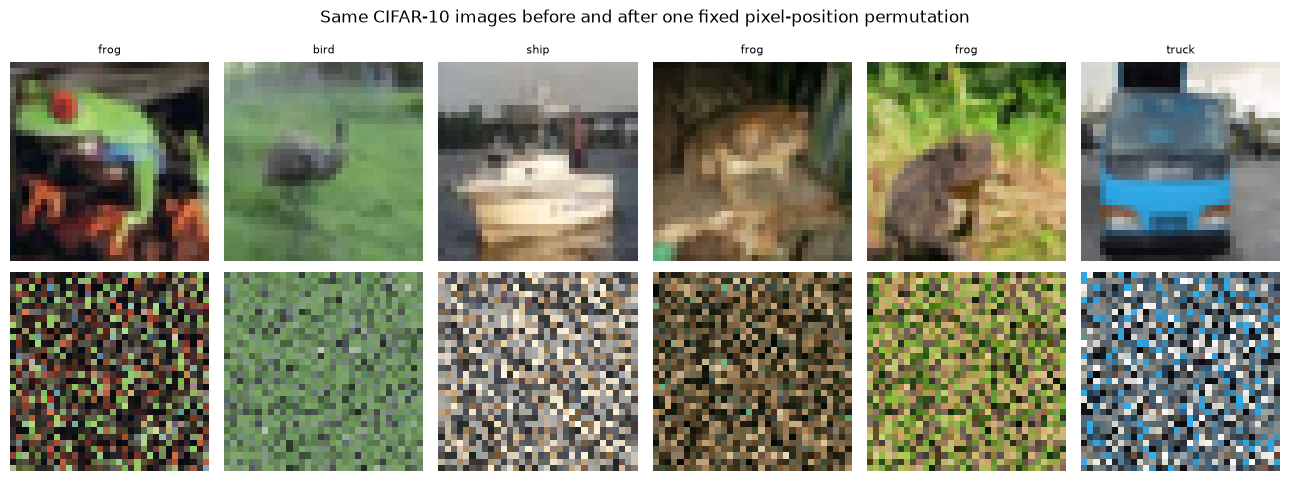

In [12]:
example_indices = split_indices[:6]
mean_tensor = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for column, index in enumerate(example_indices):
    original, label = original_train_val_dataset[index]
    shuffled, shuffled_label = train_val_dataset_shuf[index]
    assert label == shuffled_label
    original_rgb = (original * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0).numpy()
    shuffled_rgb = (shuffled * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[0, column].imshow(original_rgb)
    axes[1, column].imshow(shuffled_rgb)
    axes[0, column].set_title(train_val_dataset_shuf.classes[label], fontsize=8)
    for row in range(2):
        axes[row, column].axis("off")
axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Shuffled", fontsize=10)
fig.suptitle("Same CIFAR-10 images before and after one fixed pixel-position permutation")
fig.tight_layout()
fig.savefig(EXTRA_DIR / "shuffle_examples.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


In [13]:
class SimpleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)

if "CIFAR10CNN" not in globals():
    class CIFAR10CNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
            self.relu1 = nn.ReLU()
            self.pool1 = nn.MaxPool2d(2)
            self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
            self.relu2 = nn.ReLU()
            self.pool2 = nn.MaxPool2d(2)
            self.flatten = nn.Flatten()
            self.fc = nn.Linear(64 * 8 * 8, 10)

        def forward(self, x):
            x = self.pool1(self.relu1(self.conv1(x)))
            x = self.pool2(self.relu2(self.conv2(x)))
            return self.fc(self.flatten(x))

if "set_seed" not in globals():
    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

if "criterion" not in globals():
    criterion = nn.CrossEntropyLoss()

if "epoch_metrics" not in globals():
    def epoch_metrics(model, loader, optimizer=None):
        training_mode = optimizer is not None
        model.train(training_mode)
        loss_sum = 0.0
        correct = 0
        count = 0
        context = torch.enable_grad() if training_mode else torch.no_grad()
        with context:
            for images, labels in loader:
                try:
                    images = images.to(DEVICE, non_blocking=True)
                    labels = labels.to(DEVICE, non_blocking=True)
                    if training_mode:
                        optimizer.zero_grad(set_to_none=True)
                    logits = model(images)
                    loss = criterion(logits, labels)
                    if training_mode:
                        loss.backward()
                        optimizer.step()
                    n = labels.size(0)
                    count += n
                    loss_sum += loss.item() * n
                    correct += (logits.argmax(1) == labels).sum().item()
                except torch.cuda.OutOfMemoryError as exc:
                    if training_mode:
                        optimizer.zero_grad(set_to_none=True)
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                    raise RuntimeError("CUDA out of memory. Stopping without batch-size changes or retry.") from exc
        return loss_sum / count, correct / count

if "evaluate" not in globals():
    def evaluate(model, loader, collect_predictions=False):
        model.eval()
        loss_sum = 0.0
        correct = 0
        count = 0
        y_true, y_pred = [], []
        with torch.no_grad():
            for images, labels in loader:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                logits = model(images)
                loss = criterion(logits, labels)
                n = labels.size(0)
                count += n
                loss_sum += loss.item() * n
                predictions = logits.argmax(1)
                correct += (predictions == labels).sum().item()
                if collect_predictions:
                    y_true.extend(labels.cpu().tolist())
                    y_pred.extend(predictions.cpu().tolist())
        metrics = (loss_sum / count, correct / count)
        return (*metrics, y_true, y_pred) if collect_predictions else metrics

def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

mlp_parameter_count = count_trainable_parameters(SimpleMLP())
cnn_parameter_count = count_trainable_parameters(CIFAR10CNN())
assert mlp_parameter_count == 1_707_274, mlp_parameter_count
assert cnn_parameter_count == 60_362, cnn_parameter_count
print(f"MLP trainable parameters: {mlp_parameter_count:,}")
print(f"CNN trainable parameters: {cnn_parameter_count:,}")

rng_snapshot = {
    "python": random.getstate(),
    "numpy": np.random.get_state(),
    "torch": torch.get_rng_state(),
    "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    "cudnn_deterministic": torch.backends.cudnn.deterministic,
    "cudnn_benchmark": torch.backends.cudnn.benchmark,
}
shuffled_models = {}
shuffled_histories = {}
shuffled_metrics = {}
shuffled_training_seconds = {}
try:
    for model_name, model_class in (("MLP", SimpleMLP), ("CNN", CIFAR10CNN)):
        set_seed(SEED)
        train_loader_shuf.generator.manual_seed(SEED)
        shuffled_model = model_class().to(DEVICE)
        optimizer_shuf = torch.optim.Adam(shuffled_model.parameters(), lr=LEARNING_RATE)
        model_history = {key: [] for key in ("train_loss", "train_accuracy", "val_loss", "val_accuracy")}
        start_time = time.perf_counter()
        for epoch in range(1, EPOCHS + 1):
            train_loss, train_accuracy = epoch_metrics(shuffled_model, train_loader_shuf, optimizer_shuf)
            val_loss, val_accuracy = epoch_metrics(shuffled_model, val_loader_shuf)
            model_history["train_loss"].append(train_loss)
            model_history["train_accuracy"].append(train_accuracy)
            model_history["val_loss"].append(val_loss)
            model_history["val_accuracy"].append(val_accuracy)
            print(
                f"{model_name} shuffled | epoch {epoch}/{EPOCHS} | "
                f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
                f"validation loss {val_loss:.4f}, accuracy {val_accuracy:.4f}"
            )
        training_time = time.perf_counter() - start_time
        train_eval_loss, train_eval_accuracy = evaluate(shuffled_model, train_eval_loader_shuf)
        val_eval_loss, val_eval_accuracy = evaluate(shuffled_model, val_loader_shuf)
        shuffled_models[model_name] = shuffled_model
        shuffled_histories[model_name] = model_history
        shuffled_training_seconds[model_name] = training_time
        shuffled_metrics[model_name] = {
            "train": {"loss": train_eval_loss, "accuracy": train_eval_accuracy},
            "validation": {"loss": val_eval_loss, "accuracy": val_eval_accuracy},
        }
        print(
            f"{model_name} shuffled | evaluation-mode train accuracy {train_eval_accuracy:.4f}; "
            f"validation accuracy {val_eval_accuracy:.4f}; training time {training_time:.1f}s"
        )
finally:
    random.setstate(rng_snapshot["python"])
    np.random.set_state(rng_snapshot["numpy"])
    torch.set_rng_state(rng_snapshot["torch"])
    if rng_snapshot["cuda"] is not None:
        torch.cuda.set_rng_state_all(rng_snapshot["cuda"])
    torch.backends.cudnn.deterministic = rng_snapshot["cudnn_deterministic"]
    torch.backends.cudnn.benchmark = rng_snapshot["cudnn_benchmark"]


MLP trainable parameters: 1,707,274
CNN trainable parameters: 60,362


MLP shuffled | epoch 1/20 | train loss 1.6701, accuracy 0.4079 | validation loss 1.5556, accuracy 0.4470


MLP shuffled | epoch 2/20 | train loss 1.4768, accuracy 0.4800 | validation loss 1.4852, accuracy 0.4886


MLP shuffled | epoch 3/20 | train loss 1.3716, accuracy 0.5178 | validation loss 1.4578, accuracy 0.4900


MLP shuffled | epoch 4/20 | train loss 1.2939, accuracy 0.5428 | validation loss 1.4572, accuracy 0.4998


MLP shuffled | epoch 5/20 | train loss 1.2190, accuracy 0.5711 | validation loss 1.4220, accuracy 0.5058


... (33 outputs left out)

CNN shuffled | epoch 18/20 | train loss 0.6882, accuracy 0.7551 | validation loss 1.9428, accuracy 0.4778


CNN shuffled | epoch 19/20 | train loss 0.6679, accuracy 0.7619 | validation loss 1.9760, accuracy 0.4788


CNN shuffled | epoch 20/20 | train loss 0.6550, accuracy 0.7670 | validation loss 2.0633, accuracy 0.4754


CNN shuffled | evaluation-mode train accuracy 0.8108; validation accuracy 0.4754; training time 304.8s


In [14]:
test_dataset_shuf = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=False, transform=transform_shuf
)
assert len(test_dataset_shuf) == 10_000
test_loader_shuf = DataLoader(test_dataset_shuf, shuffle=False, **loader_args)
for model_name in ("MLP", "CNN"):
    test_loss, test_accuracy = evaluate(shuffled_models[model_name], test_loader_shuf)
    shuffled_metrics[model_name]["test"] = {"loss": test_loss, "accuracy": test_accuracy}
    print(f"{model_name} shuffled | official test loss {test_loss:.4f}; accuracy {test_accuracy:.4f} ({test_accuracy:.2%})")


MLP shuffled | official test loss 2.3003; accuracy 0.5132 (51.32%)


CNN shuffled | official test loss 2.0353; accuracy 0.4747 (47.47%)


Original results loaded without retraining:
MLP original test accuracy: 51.6500%
CNN final-epoch original test accuracy: 68.5000%


,Model,Condition,Train accuracy,Validation accuracy,Test accuracy,Train-test gap (pp),Test loss
0,MLP,Original,84.23%,51.68%,51.65%,32.58,2.1902
1,MLP,Shuffled,83.80%,50.62%,51.32%,32.48,2.3003
2,CNN,Original,92.09%,67.86%,68.50%,23.59,1.3832
3,CNN,Shuffled,81.08%,47.54%,47.47%,33.61,2.0353


,Comparison,Difference (pp)
0,MLP test accuracy drop (original minus shuffled),+0.33
1,CNN test accuracy drop (original minus shuffled),+21.03
2,"CNN minus MLP test accuracy, original data",+16.85
3,"CNN minus MLP test accuracy, shuffled data",-3.85


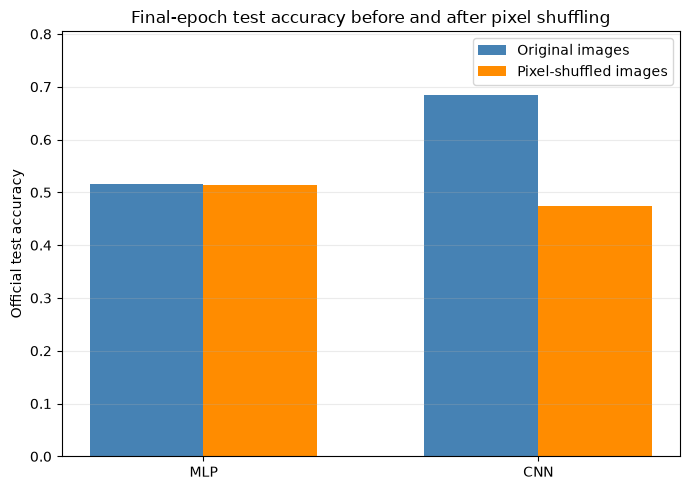

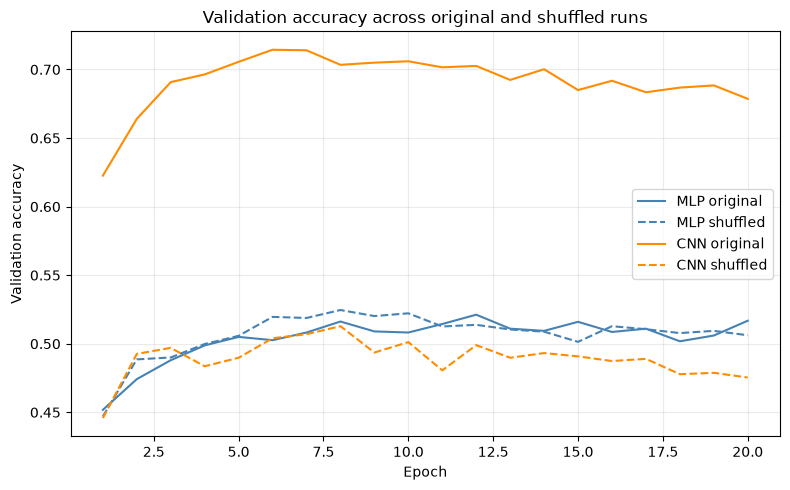

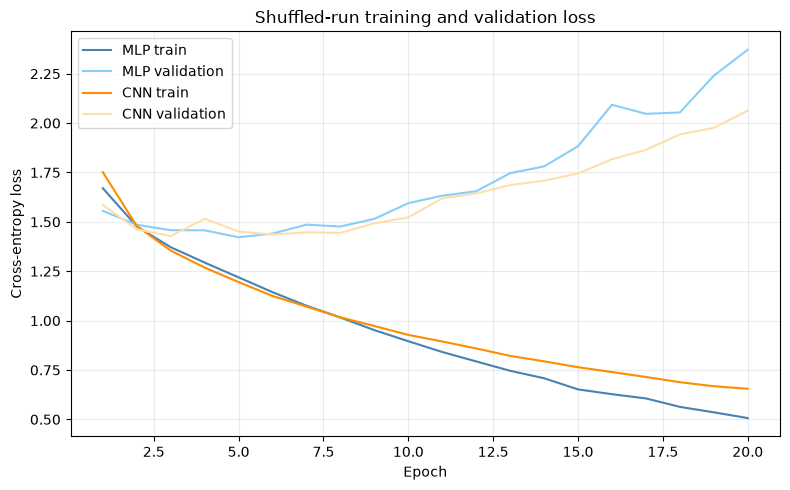

Saved additional-investigation outputs under: D:\AI ML\AI-ML-assessment-cifar10-project\artifacts\exercise_2\extra_pixel_shuffle
No checkpoints were written.


In [15]:
if "mlp_results" in globals() and "final_metrics" in mlp_results:
    original_mlp_metrics = mlp_results["final_metrics"]
else:
    original_mlp_metrics = BASELINE_MLP_RESULTS["final_metrics"]

if all(name in globals() for name in (
    "final_train_accuracy", "final_train_loss", "final_val_accuracy",
    "final_val_loss", "final_test_accuracy", "final_test_loss"
)):
    original_cnn_metrics = {
        "train": {"accuracy": final_train_accuracy, "loss": final_train_loss},
        "validation": {"accuracy": final_val_accuracy, "loss": final_val_loss},
        "test": {"accuracy": final_test_accuracy, "loss": final_test_loss},
    }
else:
    original_cnn_metrics = BASELINE_CNN_RESULTS["final_epoch"]["metrics"]

mlp_original_history = BASELINE_MLP_RESULTS["history"]
cnn_original_history = BASELINE_CNN_RESULTS["history"]

def comparison_row(model_name, condition, metrics):
    return {
        "Model": model_name,
        "Condition": condition,
        "Train accuracy": metrics["train"]["accuracy"],
        "Validation accuracy": metrics["validation"]["accuracy"],
        "Test accuracy": metrics["test"]["accuracy"],
        "Train-test gap (pp)": 100 * (metrics["train"]["accuracy"] - metrics["test"]["accuracy"]),
        "Test loss": metrics["test"]["loss"],
    }

comparison_rows = [
    comparison_row("MLP", "Original", original_mlp_metrics),
    comparison_row("MLP", "Shuffled", shuffled_metrics["MLP"]),
    comparison_row("CNN", "Original", original_cnn_metrics),
    comparison_row("CNN", "Shuffled", shuffled_metrics["CNN"]),
]
pixel_shuffle_comparison = pd.DataFrame(comparison_rows)
mlp_test_drop_pp = 100 * (
    original_mlp_metrics["test"]["accuracy"] - shuffled_metrics["MLP"]["test"]["accuracy"]
)
cnn_test_drop_pp = 100 * (
    original_cnn_metrics["test"]["accuracy"] - shuffled_metrics["CNN"]["test"]["accuracy"]
)
cnn_minus_mlp_original_pp = 100 * (
    original_cnn_metrics["test"]["accuracy"] - original_mlp_metrics["test"]["accuracy"]
)
cnn_minus_mlp_shuffled_pp = 100 * (
    shuffled_metrics["CNN"]["test"]["accuracy"] - shuffled_metrics["MLP"]["test"]["accuracy"]
)
accuracy_drop_table = pd.DataFrame([
    {"Comparison": "MLP test accuracy drop (original minus shuffled)", "Difference (pp)": mlp_test_drop_pp},
    {"Comparison": "CNN test accuracy drop (original minus shuffled)", "Difference (pp)": cnn_test_drop_pp},
    {"Comparison": "CNN minus MLP test accuracy, original data", "Difference (pp)": cnn_minus_mlp_original_pp},
    {"Comparison": "CNN minus MLP test accuracy, shuffled data", "Difference (pp)": cnn_minus_mlp_shuffled_pp},
])

print("Original results loaded without retraining:")
print(f"MLP original test accuracy: {original_mlp_metrics['test']['accuracy']:.4%}")
print(f"CNN final-epoch original test accuracy: {original_cnn_metrics['test']['accuracy']:.4%}")
display(pixel_shuffle_comparison.style.format({
    "Train accuracy": "{:.2%}", "Validation accuracy": "{:.2%}",
    "Test accuracy": "{:.2%}", "Train-test gap (pp)": "{:.2f}",
    "Test loss": "{:.4f}",
}))
display(accuracy_drop_table.style.format({"Difference (pp)": "{:+.2f}"}))

labels = ("MLP", "CNN")
x = np.arange(len(labels))
width = 0.34
original_test = [
    original_mlp_metrics["test"]["accuracy"],
    original_cnn_metrics["test"]["accuracy"],
]
shuffled_test = [
    shuffled_metrics["MLP"]["test"]["accuracy"],
    shuffled_metrics["CNN"]["test"]["accuracy"],
]
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x - width / 2, original_test, width, label="Original images", color="steelblue")
ax.bar(x + width / 2, shuffled_test, width, label="Pixel-shuffled images", color="darkorange")
ax.set_xticks(x, labels)
ax.set_ylim(0, min(1.0, max(original_test + shuffled_test) + 0.12))
ax.set_ylabel("Official test accuracy")
ax.set_title("Final-epoch test accuracy before and after pixel shuffling")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(EXTRA_DIR / "test_accuracy_original_vs_shuffled.png", dpi=160)
plt.show()
plt.close(fig)

epoch_axis = range(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(8, 5))
for name, history_data, color, linestyle in (
    ("MLP original", mlp_original_history, "steelblue", "-"),
    ("MLP shuffled", shuffled_histories["MLP"], "steelblue", "--"),
    ("CNN original", cnn_original_history, "darkorange", "-"),
    ("CNN shuffled", shuffled_histories["CNN"], "darkorange", "--"),
):
    ax.plot(epoch_axis, history_data["val_accuracy"], color=color, linestyle=linestyle, label=name)
ax.set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy across original and shuffled runs")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(EXTRA_DIR / "validation_accuracy_curves.png", dpi=160)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
for name, history_data, color in (
    ("MLP train", shuffled_histories["MLP"], "steelblue"),
    ("MLP validation", shuffled_histories["MLP"], "lightskyblue"),
    ("CNN train", shuffled_histories["CNN"], "darkorange"),
    ("CNN validation", shuffled_histories["CNN"], "navajowhite"),
):
    metric = "train_loss" if "train" in name else "val_loss"
    ax.plot(epoch_axis, history_data[metric], color=color, label=name)
ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Shuffled-run training and validation loss")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(EXTRA_DIR / "shuffled_loss_curves.png", dpi=160)
plt.show()
plt.close(fig)

result_payload = {
    "shuffle_seed": SHUFFLE_SEED,
    "permutation": perm.tolist(),
    "seed": SEED,
    "split_seed": SPLIT_SEED,
    "split_sizes": {"train": len(train_dataset_shuf), "validation": len(val_dataset_shuf), "official_test": len(test_dataset_shuf)},
    "settings": {"batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "device": str(DEVICE)},
    "parameter_counts": {"MLP": mlp_parameter_count, "CNN": cnn_parameter_count},
    "training_seconds": shuffled_training_seconds,
    "histories": shuffled_histories,
    "metrics": {
        "MLP original": original_mlp_metrics,
        "MLP shuffled": shuffled_metrics["MLP"],
        "CNN original": original_cnn_metrics,
        "CNN shuffled": shuffled_metrics["CNN"],
    },
    "comparison": pixel_shuffle_comparison.to_dict(orient="records"),
    "accuracy_differences_pp": accuracy_drop_table.to_dict(orient="records"),
}
with (EXTRA_DIR / "results.json").open("w", encoding="utf-8") as file:
    json.dump(result_payload, file, indent=2)
pixel_shuffle_comparison.to_csv(EXTRA_DIR / "comparison.csv", index=False)
print("Saved additional-investigation outputs under:", EXTRA_DIR)
print("No checkpoints were written.")


In [16]:
mlp_shuffled_accuracy = shuffled_metrics["MLP"]["test"]["accuracy"]
cnn_shuffled_accuracy = shuffled_metrics["CNN"]["test"]["accuracy"]
if cnn_test_drop_pp > mlp_test_drop_pp:
    hypothesis_conclusion = (
        f"The result supports the stated hypothesis in this run: the CNN test-accuracy drop "
        f"({cnn_test_drop_pp:+.2f} pp) exceeded the MLP drop ({mlp_test_drop_pp:+.2f} pp)."
    )
elif cnn_test_drop_pp < mlp_test_drop_pp:
    hypothesis_conclusion = (
        f"The result does not support the stated hypothesis in this run: the CNN test-accuracy "
        f"drop ({cnn_test_drop_pp:+.2f} pp) was smaller than the MLP drop ({mlp_test_drop_pp:+.2f} pp)."
    )
else:
    hypothesis_conclusion = (
        f"The measured test-accuracy drops were equal ({cnn_test_drop_pp:+.2f} pp), so this run "
        "does not show that shuffling hurt one model more."
    )

nonlocal_observation = []
if cnn_shuffled_accuracy > 0.10:
    nonlocal_observation.append(
        f"The shuffled CNN remained above the 10% chance level ({cnn_shuffled_accuracy:.2%})"
    )
if cnn_shuffled_accuracy > mlp_shuffled_accuracy:
    nonlocal_observation.append(
        f"and it still outperformed the shuffled MLP ({mlp_shuffled_accuracy:.2%})"
    )
if nonlocal_observation:
    nonlocal_text = (
        " ".join(nonlocal_observation)
        + ". This can arise from non-local effects: the 64 x 8 x 8 features still feed a dense layer, "
          "and ReLU and max-pooling still extract some pixel statistics; it is not by itself evidence of a bug."
    )
else:
    nonlocal_text = (
        f"After shuffling, CNN accuracy was {cnn_shuffled_accuracy:.2%} and MLP accuracy was "
        f"{mlp_shuffled_accuracy:.2%}; neither above-chance nor CNN-over-MLP behavior was observed."
    )

gap_change_pp = cnn_minus_mlp_shuffled_pp - cnn_minus_mlp_original_pp
if cnn_minus_mlp_original_pp > 0 and cnn_minus_mlp_shuffled_pp < 0:
    gap_interpretation = "the CNN's advantage reversed (the shuffled MLP outperformed the shuffled CNN)"
elif cnn_minus_mlp_original_pp < 0 and cnn_minus_mlp_shuffled_pp > 0:
    gap_interpretation = "the CNN's advantage reversed (the shuffled CNN outperformed the shuffled MLP)"
elif gap_change_pp > 0:
    gap_interpretation = "the CNN's relative advantage increased"
elif gap_change_pp < 0:
    gap_interpretation = "the CNN's relative advantage narrowed"
else:
    gap_interpretation = "the relative gap was unchanged"

if abs(mlp_test_drop_pp) <= 1.0:
    mlp_permutation_explanation = (
        f"The MLP's change was near zero ({mlp_test_drop_pp:+.2f} pp), which is expected for a fully connected model: "
        "a fixed pixel permutation only reorders columns of its first weight matrix, so it does not depend on pixel layout. "
        "The small remaining difference can come from initialization and data-order randomness."
    )
else:
    mlp_permutation_explanation = (
        f"The MLP changed by {mlp_test_drop_pp:+.2f} pp. A fixed pixel permutation only reorders columns of its first weight matrix, "
        "so a fully connected model does not rely on pixel layout; the measured difference reflects optimization sensitivity as well."
    )

pixel_shuffle_discussion = f"""### Pixel-shuffle investigation

On the untouched official test set, original-image accuracy was **{original_mlp_metrics['test']['accuracy']:.2%}** for the MLP and **{original_cnn_metrics['test']['accuracy']:.2%}** for the CNN. After the fixed permutation, final-epoch accuracy was **{mlp_shuffled_accuracy:.2%}** for the shuffled MLP and **{cnn_shuffled_accuracy:.2%}** for the shuffled CNN. The original-minus-shuffled accuracy drops were **{mlp_test_drop_pp:+.2f} pp** for the MLP and **{cnn_test_drop_pp:+.2f} pp** for the CNN.

{hypothesis_conclusion}

The CNN-minus-MLP test-accuracy difference changed from **{cnn_minus_mlp_original_pp:+.2f} pp** on original images to **{cnn_minus_mlp_shuffled_pp:+.2f} pp** after shuffling, a change of **{gap_change_pp:+.2f} pp**; {gap_interpretation}. {nonlocal_text}

{mlp_permutation_explanation} The shuffled CNN can remain above chance because global colour statistics and its dense classifier remain usable after convolutional and pooling operations.

The permutation moves whole pixel colour triplets together and does not change pixel values. Global colour statistics therefore remain available to both models. This is an exploratory extra, not a replacement for the main results. Its limitations are one initialization/data-order seed, one fixed permutation, one train/validation split, final-epoch models only, and no augmentation or regularisation."""
display(Markdown(pixel_shuffle_discussion))


### Pixel-shuffle investigation

On the untouched official test set, original-image accuracy was **51.65%** for the MLP and **68.50%** for the CNN. After the fixed permutation, final-epoch accuracy was **51.32%** for the shuffled MLP and **47.47%** for the shuffled CNN. The original-minus-shuffled accuracy drops were **+0.33 pp** for the MLP and **+21.03 pp** for the CNN.

The result supports the stated hypothesis in this run: the CNN test-accuracy drop (+21.03 pp) exceeded the MLP drop (+0.33 pp).

The CNN-minus-MLP test-accuracy difference changed from **+16.85 pp** on original images to **-3.85 pp** after shuffling, a change of **-20.70 pp**; the CNN's advantage reversed (the shuffled MLP outperformed the shuffled CNN). The shuffled CNN remained above the 10% chance level (47.47%). This can arise from non-local effects: the 64 x 8 x 8 features still feed a dense layer, and ReLU and max-pooling still extract some pixel statistics; it is not by itself evidence of a bug.

The MLP's change was near zero (+0.33 pp), which is expected for a fully connected model: a fixed pixel permutation only reorders columns of its first weight matrix, so it does not depend on pixel layout. The small remaining difference can come from initialization and data-order randomness. The shuffled CNN can remain above chance because global colour statistics and its dense classifier remain usable after convolutional and pooling operations.

The permutation moves whole pixel colour triplets together and does not change pixel values. Global colour statistics therefore remain available to both models. This is an exploratory extra, not a replacement for the main results. Its limitations are one initialization/data-order seed, one fixed permutation, one train/validation split, final-epoch models only, and no augmentation or regularisation.